In [6]:
import pandas as pd

# Load dataset using ../ since the notebook is inside the Src folder
df = pd.read_csv("../Data-raw/Telco-Customer-Churn-Cleaned.csv")
print(df["tenure"].describe())

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


Visualize tenure distribution

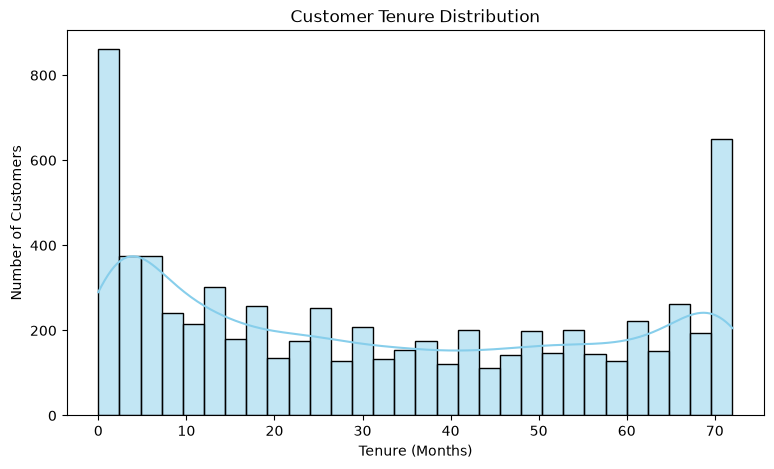

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../Data-raw/Telco-Customer-Churn-Cleaned.csv")
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    kde=True,
    color="skyblue"
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

Compare tenure for churned and retained customers

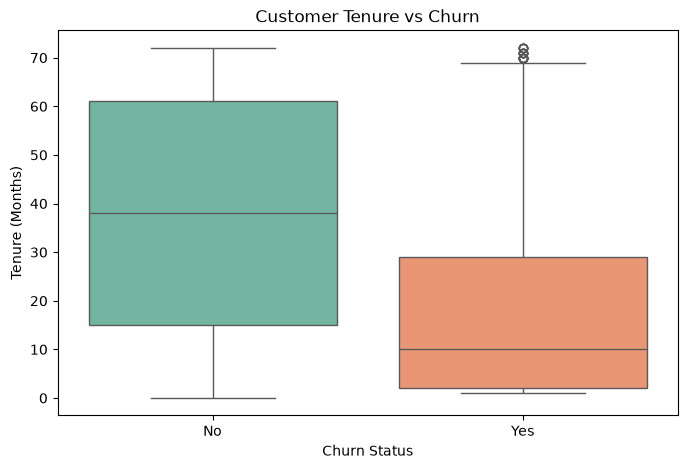

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

In [9]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

print(df["TenureGroup"].value_counts(sort=False))

TenureGroup
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64


Calculate churn rate by tenure group

In [10]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(tenure_churn.round(2))

TenureGroup
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Churn, dtype: float64


Create tenure churn rate graph

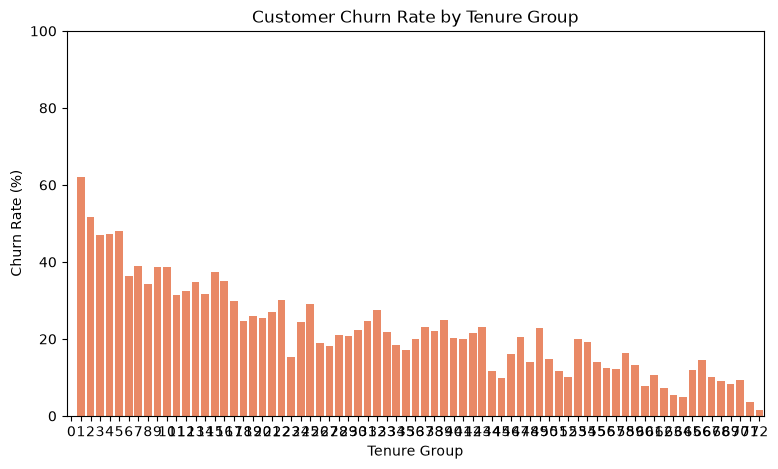

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn rate by tenure
tenure_churn = df.groupby("tenure")["Churn"].apply(lambda x: (x == "Yes").mean()) * 100

plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values,
    color="coral"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()